In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score


In [ ]:
from gps_ids import protocol, training

EXP = protocol.real_heldout("uav")
r = training.run("XGBoost", EXP)
model = r.model
y_pred = r.y_pred
y_test = EXP.y_test
feature_names = EXP.feature_names


In [7]:
# Predict and evaluate
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Model Accuracy on Test Set: {accuracy * 100:.2f}%")
print("F1 Score: {:.4f}".format(f1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy on Test Set: 99.79%
F1 Score: 0.9979
Confusion Matrix:
[[2500    0]
 [   6  392]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2500
           1       1.00      0.98      0.99       398

    accuracy                           1.00      2898
   macro avg       1.00      0.99      1.00      2898
weighted avg       1.00      1.00      1.00      2898



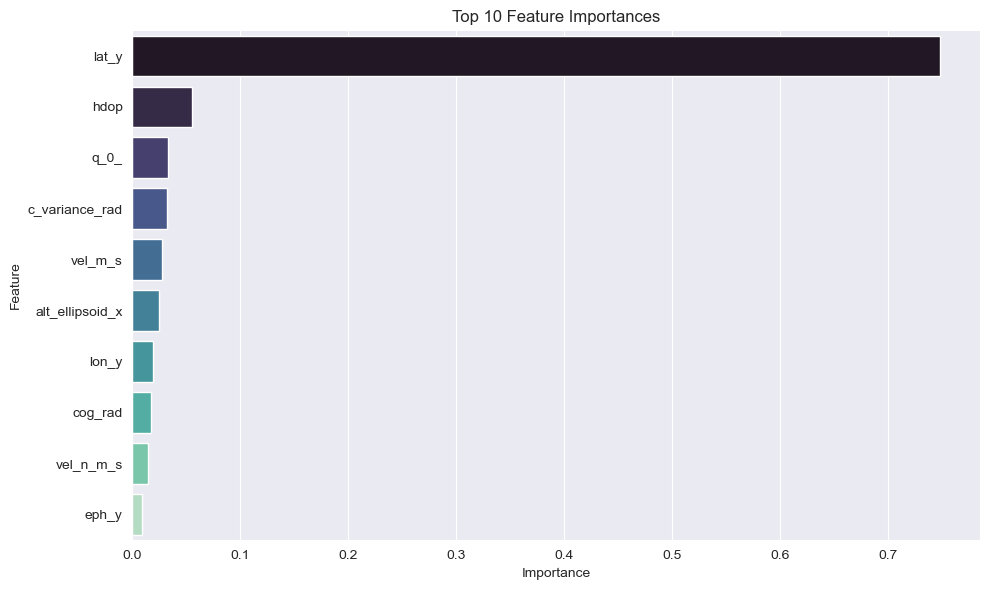

In [8]:
importances = model.feature_importances_

# Create a DataFrame for feature importances
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(10),
    x='Importance',
    y='Feature',
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=800)
plt.show()

Possibly calculated variance in rad or current, Horizontal dilution of precision, and course over ground are the most important features.